In [23]:
import os
import glob
import tifffile
import numpy as np
import matplotlib.pyplot as plt

# POINT THIS TO YOUR FOLDER
FOLDER = r"/home/students/rawat/training_data/data/train/images/"

print(f"{'Filename':<50} | {'Dtype':<8} | {'Range':<12} | Status")
print("-" * 90)

# Check both .tif and .ome.tif
print(f"🕵️ Scanning files in: {FOLDER}...")
files = sorted(glob.glob(os.path.join(FOLDER, "*.tif")))

issues_found = 0

for f in files:
    try:
        img = tifffile.imread(f)
        name = os.path.basename(f)
        
        # Check for issues: Must be uint8 AND non-negative
        is_bad = (img.dtype != np.uint8) or (img.min() < 0)
        
        if is_bad:
            print(f"❌ ISSUE FOUND: {name:<50} | Type: {img.dtype} | Range: {img.min()}-{img.max()}")
            issues_found += 1
            
    except Exception as e:
        print(f"❌ ERROR READING: {os.path.basename(f)} | {e}")
        issues_found += 1

# Final Summary
if issues_found == 0:
    print("\n✅ All files are OK! (uint8 and valid range)")
else:
    print(f"\n⚠️ Found issues in {issues_found} files.")

Filename                                           | Dtype    | Range        | Status
------------------------------------------------------------------------------------------
🕵️ Scanning files in: /home/students/rawat/training_data/data/train/images/...

✅ All files are OK! (uint8 and valid range)


ORIGINAL  : uint16 | Range: 0 to 65535
CONVERTED : uint8 | Range: 0 to 255


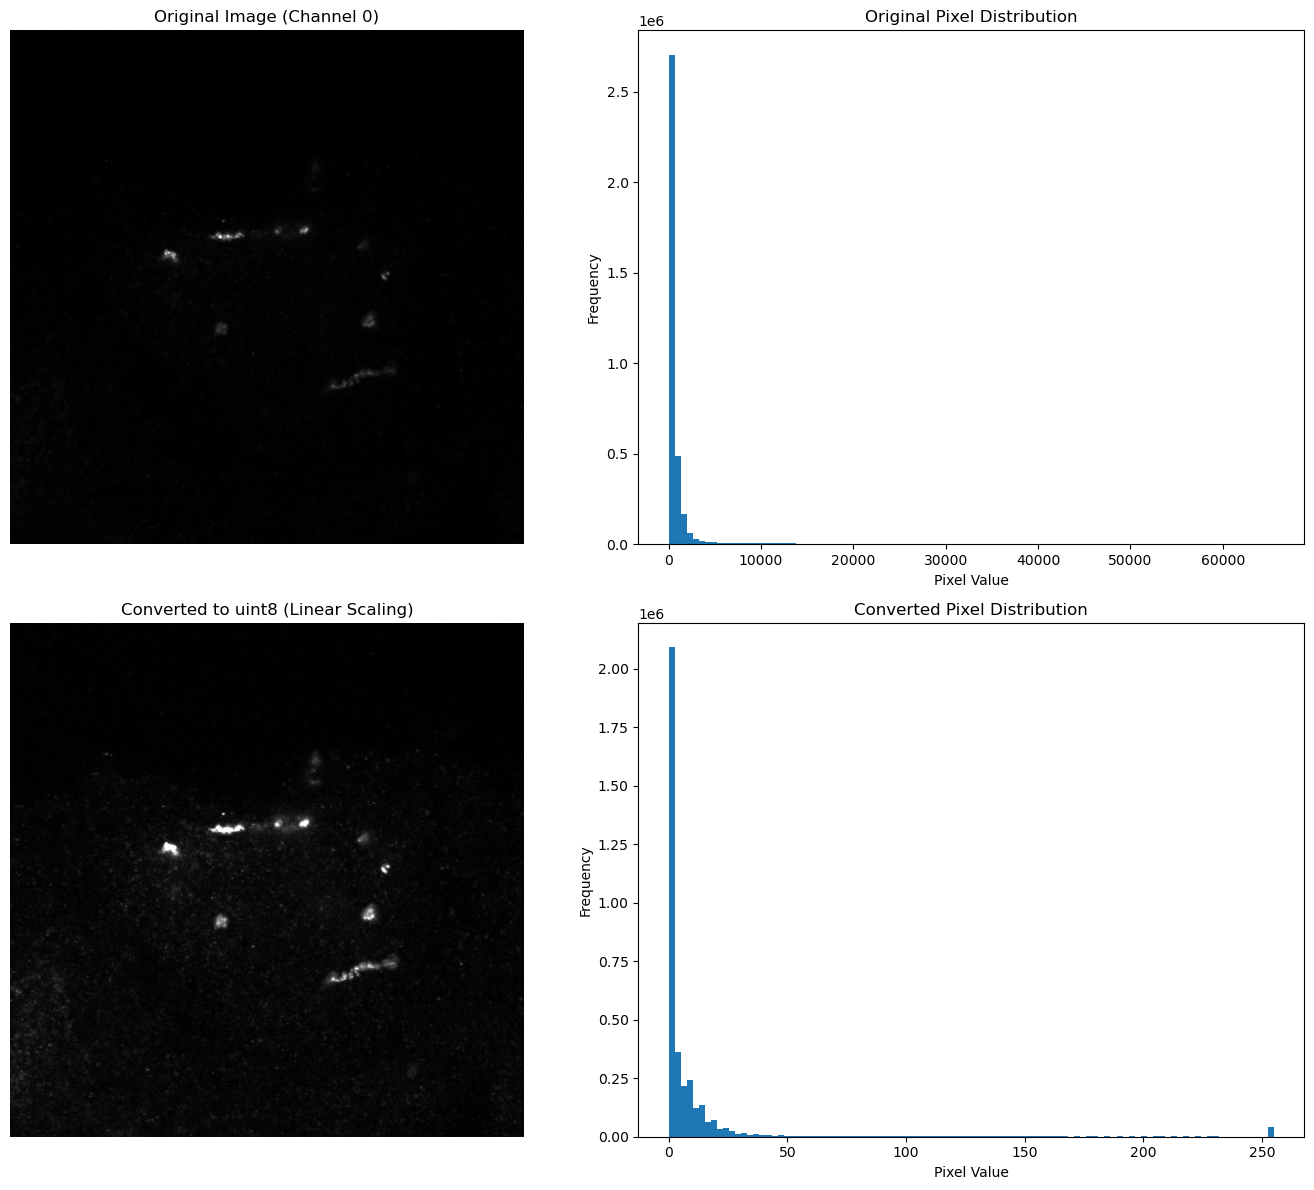

In [ ]:
INPUT_PATH = r"/home/students/rawat/training_data/data/train/images/Control_group_Brain2_PN_KC_anti_GFP_488_anti_RFP_568_LSMPlus_16bit_06.10.2025_slice_0010.tif"
img = tifffile.imread(INPUT_PATH)
print(f"ORIGINAL  : {img.dtype} | Range: {img.min()} to {img.max()}")

low, high = np.percentile(img, (1, 99))
if high > low:
    img_norm = (img.astype(float) - low) / (high - low)
    img_u8 = (np.clip(img_norm, 0, 1) * 255).astype(np.uint8)
else:
    img_u8 = img.astype(np.uint8) # Fallback if image is flat

print(f"Converted Type: {img_u8.dtype} | Range: {img_u8.min()} to {img_u8.max()}")

# 4. Plot in 2x2 grid
# fig, ax = plt.subplots(2, 2, figsize=(14, 12))

# # Top Left: Original Image
# if img.ndim == 3:
#     ax[0, 0].imshow(img[..., 0], cmap='gray')
#     ax[0, 0].set_title("Original Image (Channel 0)", fontsize=12)
# else:
#     ax[0, 0].imshow(img, cmap='gray')
#     ax[0, 0].set_title("Original Image", fontsize=12)
# ax[0, 0].axis('off')

# # Top Right: Original Histogram
# ax[0, 1].hist(img.ravel(), bins=50, color='blue', alpha=0.7)
# ax[0, 1].set_title("Original Pixel Distribution", fontsize=12)
# ax[0, 1].set_xlabel("Pixel Value")
# ax[0, 1].set_ylabel("Frequency")

# # Bottom Left: Converted Image
# if img_u8.ndim == 3:
#     ax[1, 0].imshow(img_u8[..., 0], cmap='gray')
#     ax[1, 0].set_title("Converted to uint8 (Channel 0)", fontsize=12)
# else:
#     ax[1, 0].imshow(img_u8, cmap='gray')
#     ax[1, 0].set_title("Converted to uint8", fontsize=12)
# ax[1, 0].axis('off')

# # Bottom Right: Converted Histogram
# ax[1, 1].hist(img_u8.ravel(), bins=50, color='green', alpha=0.7)
# ax[1, 1].set_title("Converted Pixel Distribution", fontsize=12)
# ax[1, 1].set_xlabel("Pixel Value")
# ax[1, 1].set_ylabel("Frequency")

# plt.tight_layout()
# plt.show()



In [20]:
print("\n--- STATISTICS ---")
print(f"Shape: {img.shape}")
print(f"Data Type (dtype): {img.dtype}")
print(f"Minimum Value: {img.min()}")
print(f"Maximum Value: {img.max()}")
print(f"Mean Value:    {img.mean():.2f}")


--- STATISTICS ---
Shape: (1101, 1101, 3)
Data Type (dtype): uint16
Minimum Value: 0
Maximum Value: 65535
Mean Value:    1078.54


In [4]:
LABEL_PATH = r"/home/students/rawat/training_data/data/train/labels/Brain2_PN_KC_Group3_25minfix_OvernightSecAB_488_561_Calyx1_Confocal_slice_0015.tif"

label = tifffile.imread(LABEL_PATH)

print(label.shape)

(1101, 1101)


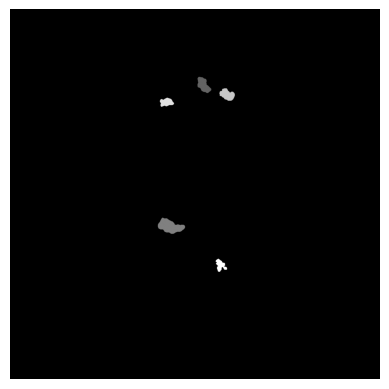

In [5]:
plt.imshow(label, cmap='gray')
plt.axis('off')
plt.show()